# Demo 3: GAMs with multiple linear predictors (Python / pymgcv)

This notebook is the Python version of [`R_demos/3_multi_gams.R`](../R_demos/3_multi_gams.R).
In a standard GAM, only the **mean** of the response depends on the covariates. Here each
example has **several linear predictors**, so other aspects of the distribution can depend
on the covariates too:

1. **GAMLSS for children's BMI**: the location, scale and skewness of BMI all change with
   age (sinh-arcsinh, or *shash*, distribution).
2. **Multivariate Gaussian model for electricity load**: two responses (load at 5pm and
   8pm) whose means *and covariance matrix* depend on the time of year (SCM package).
3. **Stacking two forecasts**: the weight given to each of two forecasting models depends
   on how well each has performed recently (gamFactory package).

## R → Python summary

| R | Python in this notebook | Notes |
|---|---|---|
| `gamV(list(...), family = shash)` | `GAM({...}, family=Shash())` | pymgcv ✅ |
| `s(age, bs = "ad")` | `S("age", bs=AdaptiveSmooth())` | ⚠️ pymgcv has no adaptive smooth basis; we define it in 5 lines |
| `check1D(fit, "age") + l_gridCheck1D(sd)` | `grid_check_1d(..., stat=np.std)` helper | ⚠️ not in pymgcv, built with numpy/matplotlib |
| `fit$family$qf(p, pr)` | `shash_quantile()` helper | numpy/scipy |
| `plot(fit3)` | `gplt.plot(fit3)` | pymgcv ✅ |
| `gam_scm(..., family = mvn_scm(d = 2))` with constant covariance | `GAM({...}, family=MVN(d=2))` | pymgcv ✅ (mgcv's `mvn` family) |
| `gam_scm(...)` with covariance depending on covariates (`Th_11 ~ s(doy)`, ...) | rpy2 + SCM | ❌ not possible in pymgcv/mgcv |
| `ALE(fit, ...)` | rpy2 + mgcViz | ❌ not in pymgcv |
| `gam(..., family = fam_stackProb(...))` | rpy2 + gamFactory | ❌ not in pymgcv |
| `dmvn()` + `contour()` | `scipy.stats.multivariate_normal` + `plt.contour` | scipy ✅ |
| `group_by() %>% summarise()` | `pandas.groupby()` | pandas ✅ |

> **Requirements:** this notebook uses the R packages `testGam`, `SCM` and `gamFactory`,
> which are only on GitHub. Install them once with `pixi run install-r-github` (see the
> README).

In [1]:
%matplotlib inline
import tempfile
from dataclasses import dataclass

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import rpy2.robjects as ro
from IPython.display import Image, display
from rpy2.robjects.packages import importr
from scipy.stats import multivariate_normal, norm

import pymgcv.plot as gplt
from pymgcv.basis_functions import AbstractBasis
from pymgcv.families import MVN, Shash
from pymgcv.gam import GAM
from pymgcv.rpy_utils import to_py
from pymgcv.terms import L, S

# R packages, used through rpy2
grdevices = importr("grDevices")
for pkg in ["mgcViz", "testGam", "SCM", "gamFactory"]:
    importr(pkg)
# Hide a ggplot2 deprecation warning triggered inside mgcViz
ro.r("options(lifecycle_verbosity = 'quiet')")

rng = np.random.default_rng(1)

## Helper functions

- `show_r_plot(r_code)`: runs R plotting code and shows the figure in the notebook (as in
  Demo 2).
- `r_data(name)`: loads a dataset from the R packages into a pandas `DataFrame`.
- `grid_check_1d(x, res, sims, stat)`: Python version of
  `check1D(fit, x) + l_gridCheck1D(stat)`. It splits `x` into bins and computes `stat` of
  the residuals in each bin, for the observed residuals (black dots) and for residuals
  simulated from the fitted model (grey dots, with the red band containing 80% of them).
  If the model is right, the black dots should be inside the band.

  Unlike in mgcViz, the residuals and the simulations are passed in explicitly, because
  each model in this demo needs a different kind of residual (computed by the functions
  in each section).

In [2]:
def show_r_plot(r_code, width=7, height=5, res=100):
    """Run R plotting code and display the resulting figure in the notebook."""
    with tempfile.NamedTemporaryFile(suffix=".png", delete=False) as f:
        path = f.name
    grdevices.png(path, width=width, height=height, units="in", res=res)
    try:
        ro.r(r_code)
    finally:
        grdevices.dev_off()
    display(Image(path))


def r_data(name):
    """Load a dataset from the attached R packages as a pandas DataFrame."""
    ro.r(f"data({name})")
    return to_py(ro.r(name)).reset_index(drop=True)


def grid_check_1d(x, res, sims, stat=None, n=20, level=0.8, ax=None, xlabel="x",
                  ylabel=None):
    """Python version of mgcViz's check1D(fit, x) + l_gridCheck1D(stat).

    x: covariate, shape (n_obs,)
    res: observed residuals, shape (n_obs,) or (n_obs, d)
    sims: simulated residuals, shape (n_sim, n_obs) or (n_sim, n_obs, d)
    stat: function applied to the residuals in each bin. The default, as in mgcViz,
        is sum(r) / sqrt(count), i.e. the mean residual times sqrt(count).
    """
    if stat is None:
        def stat(r):
            return r.sum() / np.sqrt(len(r))

    x = np.asarray(x, dtype=float)
    grid = np.linspace(x.min(), x.max(), n)
    bins = np.clip(np.searchsorted(grid, x, side="right") - 1, 0, n - 2)
    used = np.unique(bins)

    x_mid = np.array([x[bins == b].mean() for b in used])
    obs = np.array([stat(res[bins == b]) for b in used])
    sim_stats = np.array([[stat(s[bins == b]) for b in used] for s in sims])
    lo, hi = np.quantile(sim_stats, [(1 - level) / 2, (1 + level) / 2], axis=0)

    ax = plt.gca() if ax is None else ax
    ax.scatter(np.tile(x_mid, len(sims)), sim_stats.ravel(), s=1, color="grey", alpha=0.5)
    ax.plot(x_mid, lo, "--", color="red")
    ax.plot(x_mid, hi, "--", color="red")
    ax.scatter(x_mid, obs, color="black", zorder=3)
    ax.set(xlabel=xlabel, ylabel=ylabel or getattr(stat, "__name__", "stat"))
    return ax

# Part 1: GAMLSS for children's BMI

## The data

`dbbmi` contains the **age** (in years) and **body mass index (BMI)** of Dutch boys.
BMI changes with age in a complex way, and so does its spread and its skewness, which
makes it a good example for a GAMLSS model.

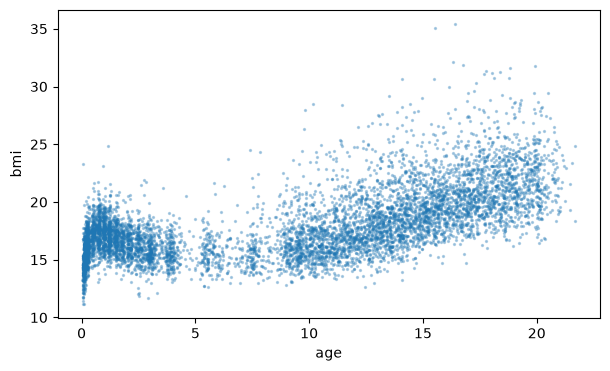

In [3]:
dbbmi_all = r_data("dbbmi")

fig, ax = plt.subplots(figsize=(7, 4))
ax.scatter(dbbmi_all["age"], dbbmi_all["bmi"], s=2, alpha=0.3)
ax.set(xlabel="age", ylabel="bmi");

As in R, we use a random sample of 2000 children, sorted by age. We draw the sample in R
with the same seed (`set.seed(151)`), so that the Python and R demos use exactly the same
data.

In [4]:
ro.r("""
set.seed(151)
dbbmi <- dbbmi[sample(1:nrow(dbbmi), 2000), ]
dbbmi <- dbbmi[order(dbbmi$age), ]
""")
dbbmi = to_py(ro.r("dbbmi")).reset_index(drop=True)
dbbmi.describe()

,age,bmi
count,2000.000000,2000.000000
mean,9.512300,18.108378
std,6.746052,2.966522
min,0.050000,11.889471
25%,1.962500,15.956094
50%,10.745000,17.496268
75%,15.392500,19.684877
max,21.450000,31.566311


## fit1: a Gaussian GAM with an adaptive smooth

BMI changes very quickly in the first year of life and slowly afterwards. An **adaptive
smooth** (`bs = "ad"` in mgcv) lets the amount of smoothing vary along `age`: wiggly where
the data need it and smooth elsewhere.

> ⚠️ **pymgcv limitation:** pymgcv has no class for the adaptive smooth. But a basis in
> pymgcv only has to tell mgcv its name (`"ad"`) and any extra arguments, so we can define
> it ourselves by subclassing `AbstractBasis`:

In [5]:
@dataclass
class AdaptiveSmooth(AbstractBasis):
    """mgcv's adaptive smooth, s(x, bs = "ad")."""

    def __str__(self) -> str:
        return "ad"  # the mgcv name of the basis

    def _pass_to_s(self) -> dict:
        return {}  # no extra arguments (m, xt) for s()

R:

```r
fit1 <- gamV(bmi ~ s(age, bs = "ad", k = 20),
             data = dbbmi,
             aViz = list(nsim = 50))
```

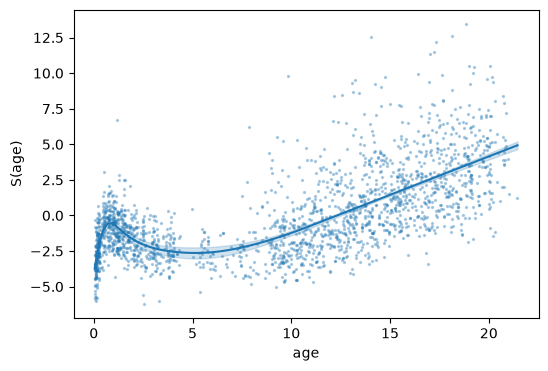

In [6]:
bmi1 = GAM({"bmi": [S("age", bs=AdaptiveSmooth(), k=20)]})
bmi1.fit(dbbmi)

fig, ax = plt.subplots(figsize=(6, 4))
gplt.continuous_1d(term=0, gam=bmi1, ax=ax, residuals=True,
                   scatter_kwargs={"s": 2, "alpha": 0.3});

### Checking the mean and the variance

For a Gaussian model we use deviance residuals, and simulate new responses from the
fitted model (as `getViz(nsim = 50)` does in R).

- `l_gridCheck1D()` (default statistic: mean residual) checks the **mean**. Almost all
  the black dots are inside the band, so the mean is modelled well.
- `l_gridCheck1D(sd)` checks the **standard deviation** of the residuals in each age bin.
  The black dots are outside the band: the spread of BMI changes with age, but a Gaussian
  GAM assumes it's constant.

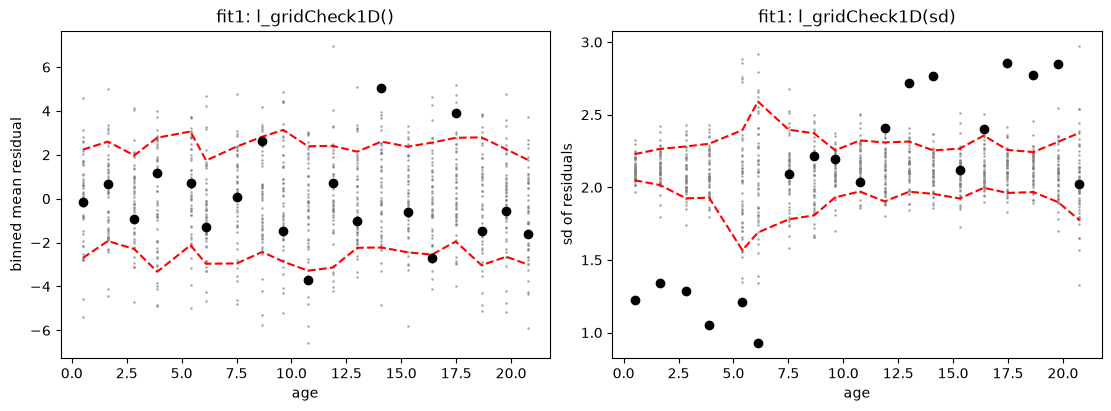

In [7]:
def simulate_residuals(fit, n_sim=50, seed=1):
    """Deviance residuals of n_sim responses simulated from a fitted pymgcv GAM."""
    ro.r(f"set.seed({seed})")
    rgam = fit.fit_state.rgam
    mu = np.array(ro.r["fitted"](rgam))
    wt = np.array(ro.r["weights"](rgam, type="prior"))
    scale = np.array(rgam.rx2("sig2"), dtype=float)
    return np.array([
        fit.residuals_from_y_and_fit(y=fit.family.sample(mu=mu, wt=wt, scale=scale),
                                     fit=mu, weights=wt)
        for _ in range(n_sim)
    ])


res1 = bmi1.residuals()
sims1 = simulate_residuals(bmi1)

fig, axes = plt.subplots(1, 2, figsize=(11, 4), layout="constrained")
grid_check_1d(dbbmi["age"], res1, sims1, ax=axes[0], xlabel="age",
              ylabel="binned mean residual")
grid_check_1d(dbbmi["age"], res1, sims1, stat=np.std, ax=axes[1], xlabel="age",
              ylabel="sd of residuals")
axes[0].set_title("fit1: l_gridCheck1D()")
axes[1].set_title("fit1: l_gridCheck1D(sd)");

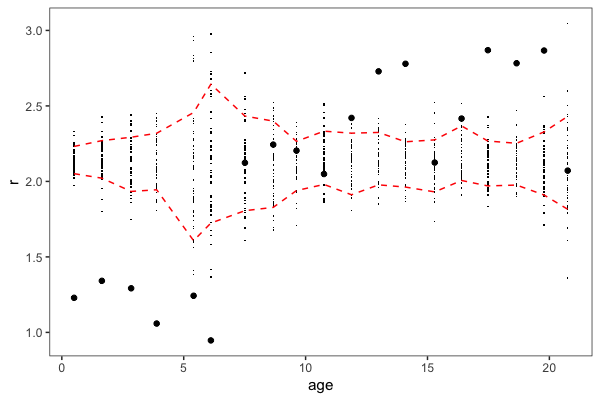

In [8]:
# The same sd check with mgcViz, through rpy2
ro.globalenv["bmi1"] = bmi1.fit_state.rgam
ro.r("set.seed(1); bmi1_viz <- getViz(bmi1, nsim = 50)")
show_r_plot('print(check1D(bmi1_viz, "age") + l_gridCheck1D(sd))', width=6, height=4)

## fit2: a shash GAMLSS model

The **sinh-arcsinh (shash)** distribution has four parameters, and each gets its own
linear predictor:

| Parameter | Controls | fit2 |
|---|---|---|
| location μ | where the distribution is centred | `s(age, bs = "ad", k = 20)` |
| scale σ | its spread | `s(age)` |
| skewness ε | its asymmetry | constant (intercept only) |
| kurtosis δ | how heavy the tails are | constant (intercept only) |

R:

```r
fit2 <- gamV(list(bmi ~ s(age, bs = "ad", k = 20),  # Location
                      ~ s(age),                     # Scale
                      ~ 1,                          # Skewness
                      ~ 1),                         # Kurtosis
             data = dbbmi, family = shash, aViz = list(nsim = 50))
```

In pymgcv, each linear predictor is one entry of the dictionary. The first key must be the
response (`"bmi"`); the others are just names we choose. An empty list means
"intercept only" (`~ 1`).

In [9]:
bmi2 = GAM(
    {
        "bmi": [S("age", bs=AdaptiveSmooth(), k=20)],  # location
        "scale": [S("age")],                           # scale
        "skew": [],                                    # skewness: ~ 1
        "kurt": [],                                    # kurtosis: ~ 1
    },
    family=Shash(),
)
bmi2.fit(dbbmi)

GAM(
  predictors={'bmi': [S(varnames=('age',),
           by=None,
           k=20,
           bs=AdaptiveSmooth(),
           id=None,
           fx=False),
         Intercept(varnames=(), by=None)],
 'kurt': [Intercept(varnames=(), by=None)],
 'scale': [S(varnames=('age',), by=None, k=None, bs=None, id=None, fx=False),
           Intercept(varnames=(), by=None)],
 'skew': [Intercept(varnames=(), by=None)]},
  family=Shash(),
  fit_state=FitState(rgam=mgcv.gam, data=DataFrame),
  add_intercepts=True,
)

### Residuals for the shash model

For distributions with a known CDF, mgcViz uses **normalised** residuals:
$r = \Phi^{-1}\{F(y)\}$, where $F$ is the fitted CDF and $\Phi^{-1}$ the standard normal
quantile function. If the model is right, these are standard normal, so we can simulate
them directly as $N(0, 1)$ draws.

For the shash distribution this has a simple form. pymgcv's `predict()` returns the four
**linear predictors**, which we first transform to the parameters:

- $\mu$ = location (identity link),
- $\sigma = e^{\eta_2} + b$, with $b = 0.01$ (the `logeb` link of the scale),
- $\epsilon$ = skewness (identity link),
- $\delta = e^{\eta_4}$.

Then, with $z = (y - \mu)/(\sigma\delta)$, the normalised residual is
$r = \sinh\{\delta \sinh^{-1}(z) - \epsilon\}$.

In [10]:
def shash_params(fit, data=None):
    """mu, sigma, epsilon, delta of a fitted pymgcv Shash GAM."""
    eta = fit.predict(data)
    mu, eta_scale, eps, eta_kurt = (np.asarray(v) for v in eta.values())
    b = 0.01  # Shash(b=0.01) default
    return mu, np.exp(eta_scale) + b, eps, np.exp(eta_kurt)


def shash_residuals(fit):
    """Normalised residuals Phi^-1(F(y)) of a shash model (standard normal if correct)."""
    mu, sigma, eps, delta = shash_params(fit)
    y = fit.fit_state.data[list(fit.predictors)[0]].to_numpy()
    z = (y - mu) / (sigma * delta)
    return np.sinh(delta * np.arcsinh(z) - eps)


def third_moment(r):
    """mean(r^3): checks the skewness of the residuals."""
    return np.mean(r**3)


res2 = shash_residuals(bmi2)
sims2 = rng.standard_normal((50, len(res2)))

The **sd** check is now fine: the scale depends on age. But the check of the **third
moment**, `mean(x^3)`, which measures skewness, shows that the skewness also changes with
age.

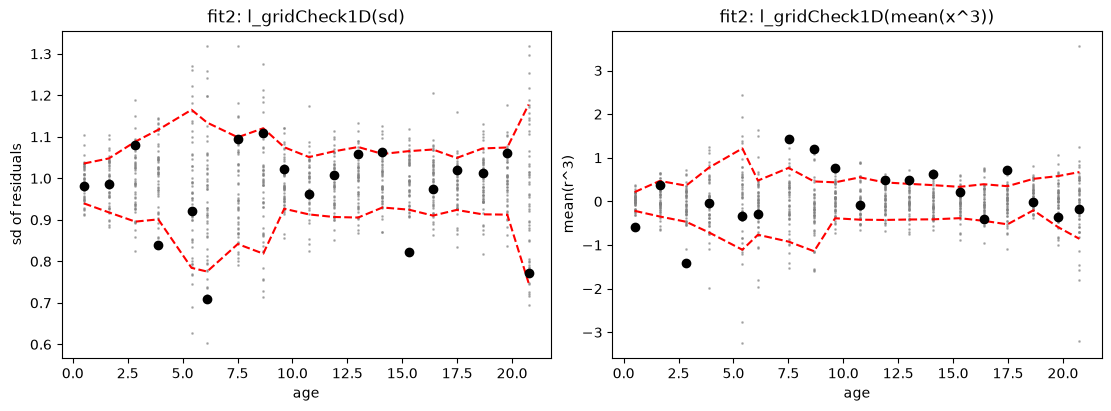

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4), layout="constrained")
grid_check_1d(dbbmi["age"], res2, sims2, stat=np.std, ax=axes[0], xlabel="age",
              ylabel="sd of residuals")
grid_check_1d(dbbmi["age"], res2, sims2, stat=third_moment, ax=axes[1], xlabel="age",
              ylabel="mean(r^3)")
axes[0].set_title("fit2: l_gridCheck1D(sd)")
axes[1].set_title("fit2: l_gridCheck1D(mean(x^3))");

## fit3: skewness depending on age

R:

```r
fit3 <- gamV(list(bmi ~ s(age, bs = "ad", k = 20), ~ s(age), ~ s(age), ~ 1),
             data = dbbmi, family = shash, aViz = list(nsim = 50))
```

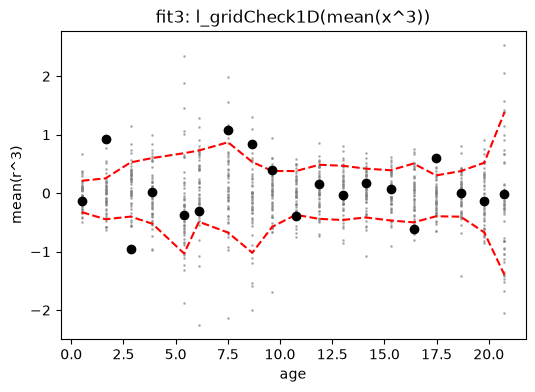

In [12]:
bmi3 = GAM(
    {
        "bmi": [S("age", bs=AdaptiveSmooth(), k=20)],  # location
        "scale": [S("age")],                           # scale
        "skew": [S("age")],                            # skewness: now a smooth of age
        "kurt": [],                                    # kurtosis: ~ 1
    },
    family=Shash(),
)
bmi3.fit(dbbmi)

res3 = shash_residuals(bmi3)
sims3 = rng.standard_normal((50, len(res3)))

fig, ax = plt.subplots(figsize=(6, 4))
grid_check_1d(dbbmi["age"], res3, sims3, stat=third_moment, ax=ax, xlabel="age",
              ylabel="mean(r^3)")
ax.set_title("fit3: l_gridCheck1D(mean(x^3))");

The third-moment check is now fine. `gplt.plot` shows the smooth effects of all the linear
predictors; the title of each panel is the name of its predictor.

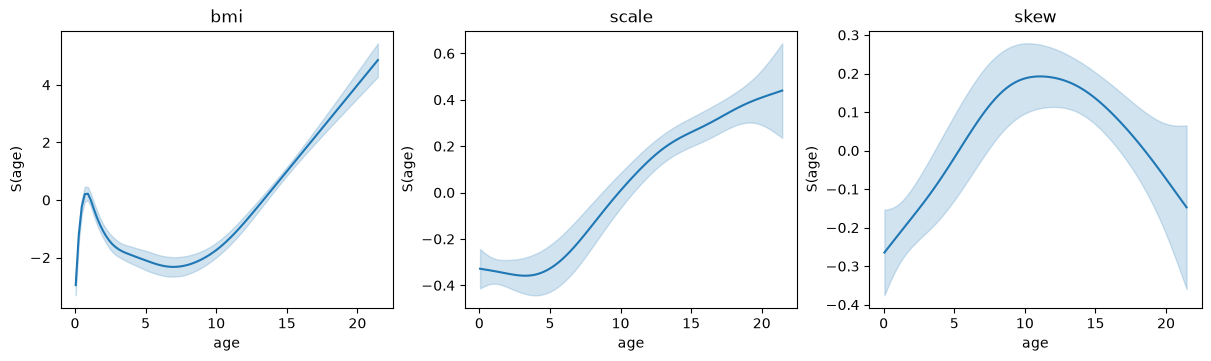

In [13]:
fig, _ = gplt.plot(bmi3, ncols=3)
fig.set_size_inches(12, 3.5)

### Fitted quantiles

Finally, we plot the fitted quantiles of BMI as a function of age. The quantile function
of the shash distribution is

$$
q_p = \mu + \sigma\delta \, \sinh\left\{\frac{\sinh^{-1}(\Phi^{-1}(p)) + \epsilon}{\delta}\right\}.
$$

> Note: the R demo calls `fit3$family$qf(.q, predict(fit3))`, which passes the linear
> predictor of the scale instead of $\log\sigma = \log(e^{\eta_2} + b)$. The difference is
> tiny ($b = 0.01$), so the curves look the same; here we use the exact transformation.

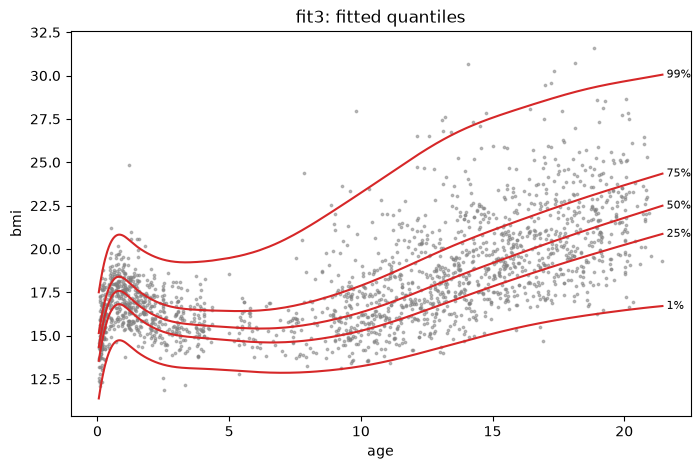

In [14]:
def shash_quantile(p, mu, sigma, eps, delta):
    """Quantile function of the shash distribution."""
    return mu + sigma * delta * np.sinh((np.arcsinh(norm.ppf(p)) + eps) / delta)


params = shash_params(bmi3)

fig, ax = plt.subplots(figsize=(8, 5))
ax.scatter(dbbmi["age"], dbbmi["bmi"], s=3, color="grey", alpha=0.5)
for p in [0.01, 0.25, 0.5, 0.75, 0.99]:
    ax.plot(dbbmi["age"], shash_quantile(p, *params), color="C3")
    ax.annotate(f"{p:.0%}", (dbbmi["age"].iloc[-1], shash_quantile(p, *params)[-1]),
                xytext=(3, 0), textcoords="offset points", va="center", fontsize=8)
ax.set(xlabel="age", ylabel="bmi", title="fit3: fitted quantiles");

# Part 2: multivariate Gaussian model for electricity load (SCM)

## The data

`GEF14_d4` (from the SCM package) has one row per day of electricity load data from the
GEFCom 2014 competition. We model the load at two hours of the day jointly:

- **`load_h17`**, **`load_h20`**: load at 17:00 (5pm) and 20:00 (8pm). These are the two
  **responses**.
- **`load24_h17`**, **`load24_h20`**: load at the same hour on the previous day.
- **`temp_h17`**, **`temp_h20`**: temperature at those hours.
- **`doy`**: day of the year; **`dow`**: day of the week (a factor); **`year`**.

In [15]:
gef = r_data("GEF14_d4")
gef["dow"] = gef["dow"].astype("category")

cols = ["year", "doy", "dow", "load_h17", "load_h20", "load24_h17", "load24_h20",
        "temp_h17", "temp_h20"]
gef[cols].head().round(2)

,year,doy,dow,load_h17,load_h20,load24_h17,load24_h20,temp_h17,temp_h20
0,2005,3.0,1,102.2,95.0,107.9,99.2,8.75,7.22
1,2005,4.0,2,93.9,79.9,102.2,95.0,13.61,13.75
2,2005,5.0,3,84.1,69.8,93.9,79.9,15.97,14.31
3,2005,6.0,4,85.7,73.7,84.1,69.8,14.03,14.86
4,2005,7.0,5,81.8,67.1,85.7,73.7,17.36,16.25


## fit1: two means, constant covariance

The two responses are modelled with a **bivariate Gaussian** distribution. Each mean has its
own linear predictor, and the 2×2 covariance matrix (two variances and a correlation) is
constant.

R (SCM package):

```r
fit1 <- gam_scm(list(load_h17 ~ dow + s(doy, k = 15) + load24_h17 + s(temp_h17),
                     load_h20 ~ dow + s(doy, k = 15) + load24_h20 + s(temp_h20)),
                family = mvn_scm(d = 2), data = GEF14_d4)
```

This model, with a constant covariance, is also available in mgcv as the `mvn` family, so
we can fit it with pymgcv using `MVN(d=2)`. Each key of the dictionary is one response.

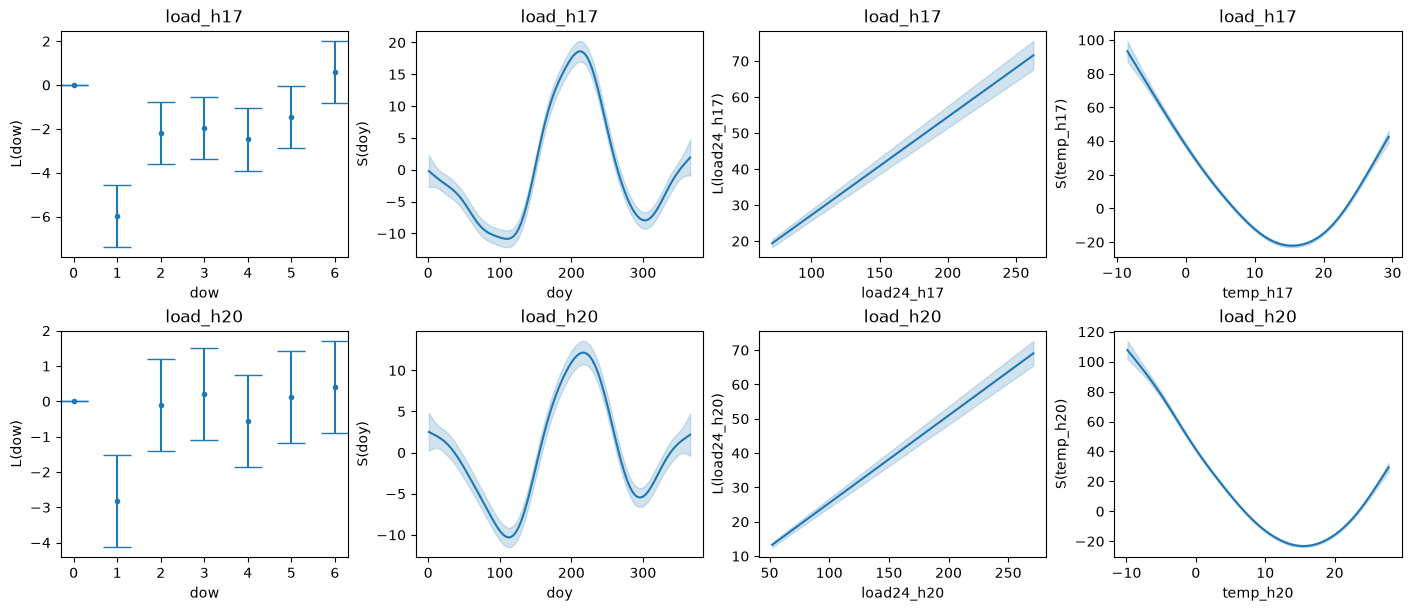

In [16]:
gef1 = GAM(
    {
        "load_h17": [L("dow"), S("doy", k=15), L("load24_h17"), S("temp_h17")],
        "load_h20": [L("dow"), S("doy", k=15), L("load24_h20"), S("temp_h20")],
    },
    family=MVN(d=2),
)
gef1.fit(gef)

fig, _ = gplt.plot(gef1, ncols=4)
fig.set_size_inches(14, 6)

`predict(fit1, type = "response")` in SCM returns 5 columns: the two means, the two
variances and the correlation. pymgcv's `predict()` gives the two means; the constant
covariance matrix is stored in the mgcv object (as the Cholesky factor `R` of its inverse).

In [17]:
R_chol = np.array(gef1.fit_state.rgam.rx2("family").rx2("data").rx2("R"))
Sigma1 = np.linalg.inv(R_chol.T @ R_chol)

means1 = gef1.predict()
pred1 = pd.DataFrame({
    "mu_h17": means1["load_h17"],
    "mu_h20": means1["load_h20"],
    "var_h17": Sigma1[0, 0],
    "var_h20": Sigma1[1, 1],
    "cor": Sigma1[0, 1] / np.sqrt(Sigma1[0, 0] * Sigma1[1, 1]),
})
pred1.head()

,mu_h17,mu_h20,var_h17,var_h20,cor
0,116.134175,110.243533,90.069602,76.460754,0.892569
1,104.779781,90.926843,90.069602,76.460754,0.892569
2,101.635573,86.750916,90.069602,76.460754,0.892569
3,98.920075,83.003725,90.069602,76.460754,0.892569
4,100.864954,84.696316,90.069602,76.460754,0.892569


### Is the covariance really constant?

We check the residuals $y - \hat\mu$ (one column per response) against `doy`, using
simulations from the fitted bivariate Gaussian:

- `sd` of the 5pm (h17) residuals in each bin (R: `gridFun = function(.x) sd(.x[, 1])`),
- correlation between the 5pm (h17) and 8pm (h20) residuals in each bin
  (R: `gridFun = function(.x) cor(.x)[1, 2]`).

Both depend on the time of year, so a constant covariance is not enough.

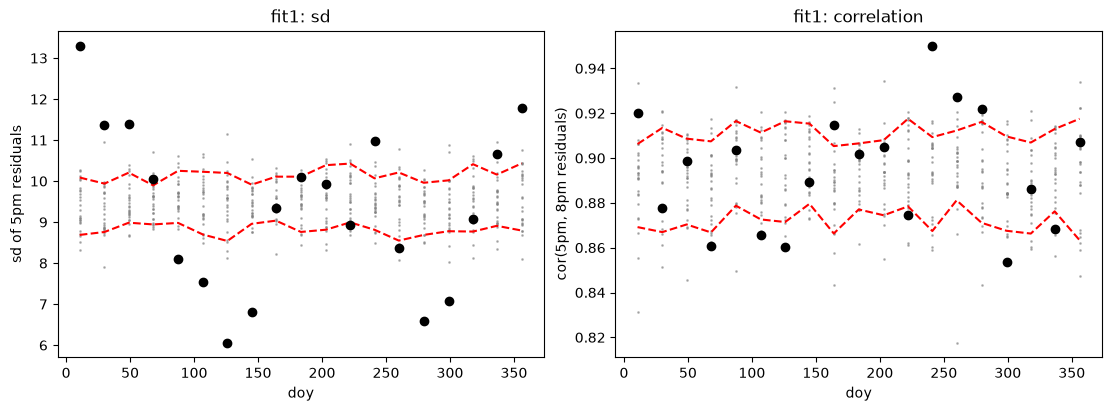

In [18]:
def mvn_residuals_and_sims(y, mu, var1, var2, cor, n_sim=25):
    """Residuals y - mu and n_sim simulated residuals from N(0, Sigma_i).

    var1, var2, cor can be scalars (constant covariance) or arrays (one per observation).
    """
    n = len(y)
    s1 = np.broadcast_to(np.sqrt(var1), n)
    s2 = np.broadcast_to(np.sqrt(var2), n)
    rho = np.broadcast_to(cor, n)
    z = rng.standard_normal((n_sim, n, 2))
    # Multiply by the Cholesky factor of each 2x2 covariance matrix
    e1 = s1 * z[..., 0]
    e2 = s2 * (rho * z[..., 0] + np.sqrt(1 - rho**2) * z[..., 1])
    return y - mu, np.stack([e1, e2], axis=-1)


def sd_h17(r):
    return np.std(r[:, 0], ddof=1)


def cor_h17_h20(r):
    return np.corrcoef(r[:, 0], r[:, 1])[0, 1]


y_gef = gef[["load_h17", "load_h20"]].to_numpy()
res_g1, sims_g1 = mvn_residuals_and_sims(
    y_gef, pred1[["mu_h17", "mu_h20"]].to_numpy(),
    pred1["var_h17"].iloc[0], pred1["var_h20"].iloc[0], pred1["cor"].iloc[0],
)

fig, axes = plt.subplots(1, 2, figsize=(11, 4), layout="constrained")
grid_check_1d(gef["doy"], res_g1, sims_g1, stat=sd_h17, ax=axes[0], xlabel="doy",
              ylabel="sd of 5pm residuals")
grid_check_1d(gef["doy"], res_g1, sims_g1, stat=cor_h17_h20, ax=axes[1], xlabel="doy",
              ylabel="cor(5pm, 8pm residuals)")
axes[0].set_title("fit1: sd")
axes[1].set_title("fit1: correlation");

## fit2: covariance depending on the day of year

SCM lets the elements of the covariance matrix depend on covariates too. `Th_11`, `Th_22`
and `Th_12` are the three parameters of the covariance matrix (by default SCM uses a
modified Cholesky decomposition, so they are unconstrained), each modelled here with a
smooth of `doy`.

> ⚠️ **pymgcv limitation:** mgcv (and so pymgcv) can only fit a multivariate Gaussian with
> a **constant** covariance. For this model we call the **SCM** package through rpy2.

> ⚠️ **SCM bug on Apple Silicon (M1/M2/M3 Macs):** SCM passes the value `-1` to C++ code
> that expects unsigned integers. On Intel processors this happens to work, but on ARM
> processors it fails with *"matrix multiplication: incompatible matrix dimensions:
> 31x2519 and 2520x1"*, also in plain R. The cell below works around it by creating a
> fixed copy of `mvn_scm()` that uses $2^{32} - 1$ instead of `-1`, which gives the same
> result on all processors. On Intel machines the fix changes nothing.

In [19]:
ro.r("""
# Work-around for the SCM bug on ARM processors (see the note above)
src <- deparse(body(SCM::mvn_scm))
stopifnot(sum(grepl("c(-1, idx_b_seq", src, fixed = TRUE)) == 1)
mvn_scm_fixed <- SCM::mvn_scm
body(mvn_scm_fixed) <- parse(text = c(
  "{", sub("c(-1, idx_b_seq", "c(4294967295, idx_b_seq", src[-c(1, length(src))], fixed = TRUE), "}"
))[[1]]
environment(mvn_scm_fixed) <- asNamespace("SCM")
""")

ro.r("""
fit2 <- gam_scm(list(load_h17 ~ dow + s(doy, k = 15) + load24_h17 + s(temp_h17),
                     load_h20 ~ dow + s(doy, k = 15) + load24_h20 + s(temp_h20),
                     Th_11 ~ s(doy),
                     Th_22 ~ s(doy),
                     Th_12 ~ s(doy)),
                family = mvn_scm_fixed(d = 2), data = GEF14_d4)
""")

# np.array (not np.asarray) copies the values out of R. np.asarray would only point to
# R's memory, which R can free and reuse once the temporary R object is gone.
pred2 = pd.DataFrame(np.array(ro.r('predict(fit2, type = "response")')),
                     columns=["mu_h17", "mu_h20", "var_h17", "var_h20", "cor"])
pred2.head()

,mu_h17,mu_h20,var_h17,var_h20,cor
0,115.687329,110.018986,247.383179,218.796141,0.945854
1,106.239496,93.140179,241.165435,214.009043,0.944348
2,103.143867,88.302517,235.114911,209.353905,0.942806
3,100.213073,85.280800,229.233280,204.832387,0.941230
4,103.474429,87.545054,223.522920,200.446734,0.939621


Now the variances and the correlation change with the day of the year, and the checks are
fine.

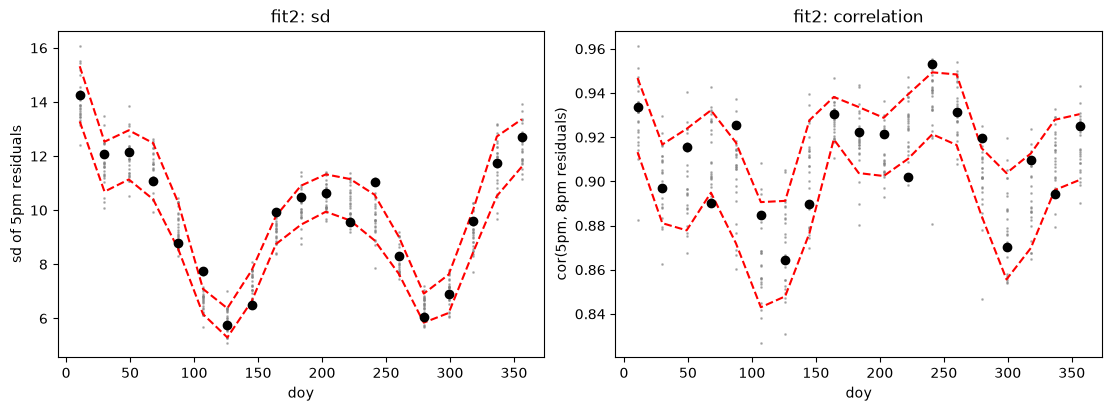

In [20]:
res_g2, sims_g2 = mvn_residuals_and_sims(
    y_gef, pred2[["mu_h17", "mu_h20"]].to_numpy(),
    pred2["var_h17"].to_numpy(), pred2["var_h20"].to_numpy(), pred2["cor"].to_numpy(),
)

fig, axes = plt.subplots(1, 2, figsize=(11, 4), layout="constrained")
grid_check_1d(gef["doy"], res_g2, sims_g2, stat=sd_h17, ax=axes[0], xlabel="doy",
              ylabel="sd of 5pm residuals")
grid_check_1d(gef["doy"], res_g2, sims_g2, stat=cor_h17_h20, ax=axes[1], xlabel="doy",
              ylabel="cor(5pm, 8pm residuals)")
axes[0].set_title("fit2: sd")
axes[1].set_title("fit2: correlation");

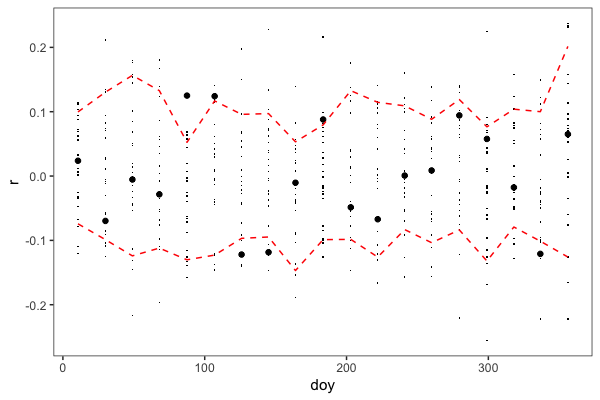

In [21]:
# The same correlation check with mgcViz, through rpy2
ro.r("set.seed(1); fit2_viz <- getViz(fit2, nsim = 25)")
show_r_plot("print(check1D(fit2_viz, 'doy') + l_gridCheck1D(gridFun = function(.x) cor(.x)[1, 2]))",
            width=6, height=4)

The smooth effects of all five linear predictors, plotted with mgcViz through rpy2
(pymgcv can't plot a model fitted by SCM):

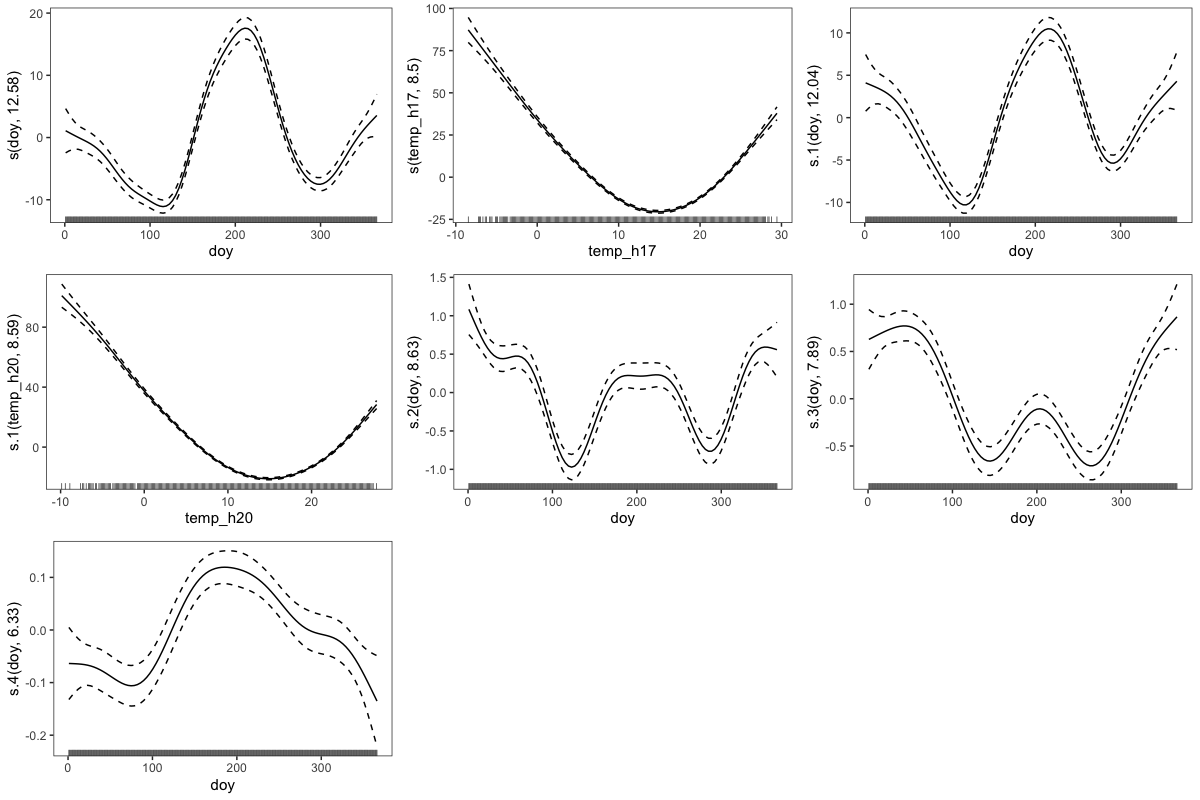

In [22]:
show_r_plot("print(plot(fit2_viz), pages = 1)", width=12, height=8)

### Accumulated local effects (ALE)

The smooths of `Th_11`, `Th_22` and `Th_12` are hard to interpret, because they act on
the covariance matrix through a decomposition. **ALE** plots (from mgcViz) show instead
how a covariate affects a quantity on the **response scale**: here, how `doy` affects the
variance of the 5pm load (`oind = 3`) and the correlation between the two hours
(`oind = 5`). There is no ALE function in pymgcv, so we use mgcViz through rpy2.

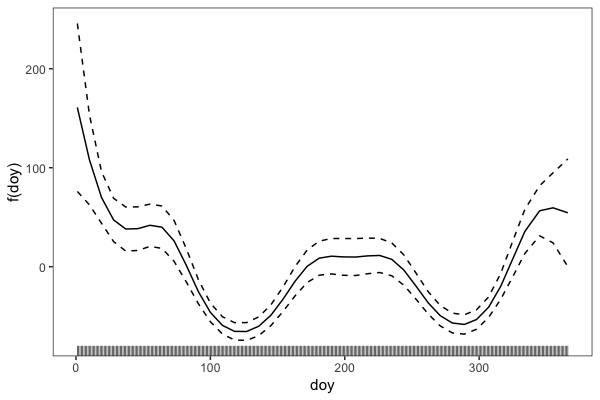

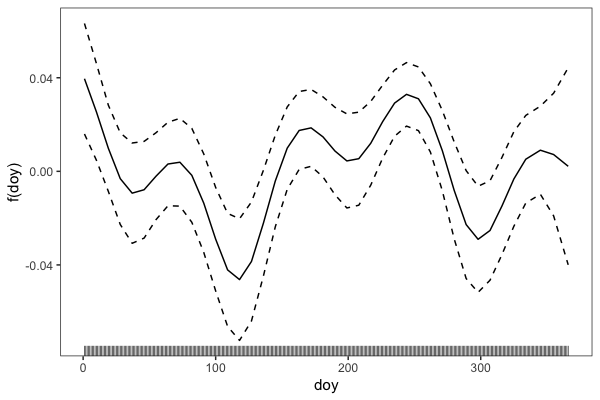

In [23]:
show_r_plot('print(plot(ALE(fit2_viz, oind = 3, x = "doy", type = "response")))',
            width=6, height=4)
show_r_plot('print(plot(ALE(fit2_viz, oind = 5, x = "doy", type = "response")))',
            width=6, height=4)

### Visualising the covariance

Each day has its own fitted covariance matrix. We draw the density of the bivariate
Gaussian (centred at 0) as contours, for a few days across the year. A narrow ellipse along
the diagonal means a strong correlation between the 5pm and 8pm load.

In R, the demo draws one day at a time and moves forward with `ii <- ii + 10`; here
`plot_covariance(ii)` draws day `ii`, and we show several days side by side.

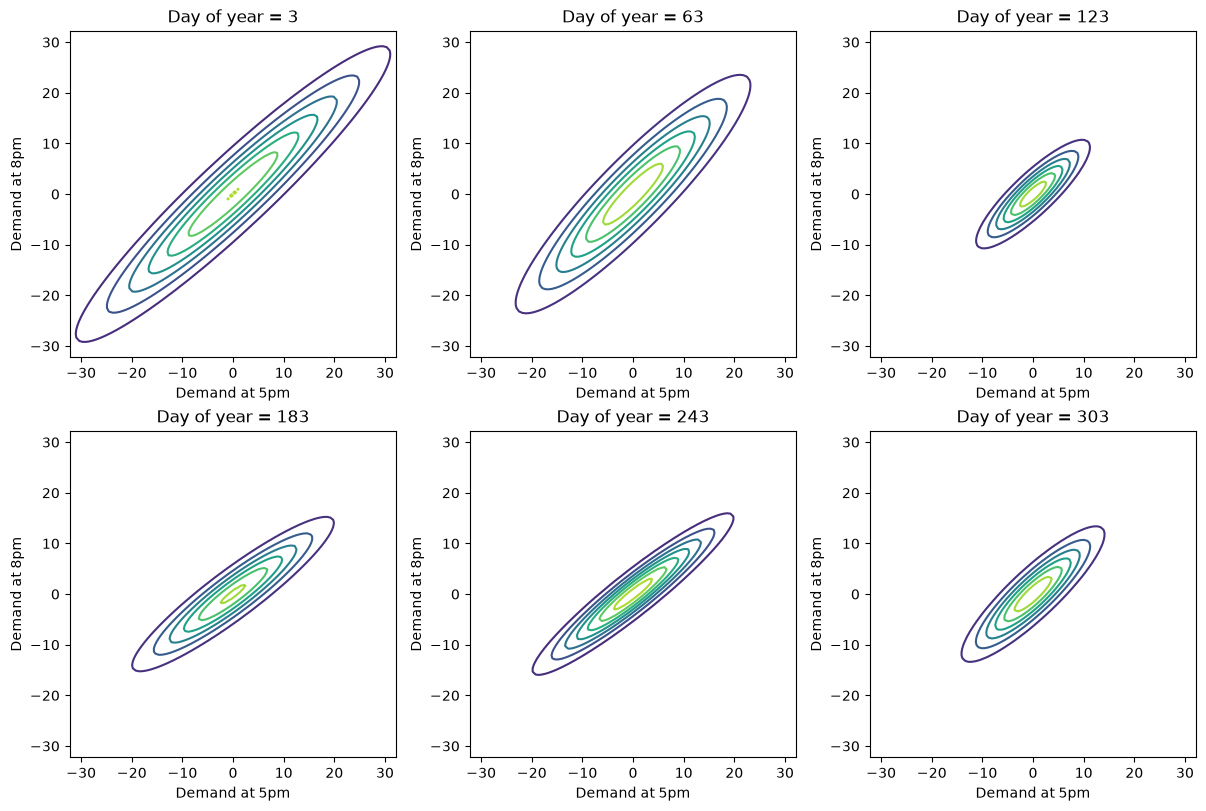

In [24]:
lim = 2 * np.sqrt(pred2[["var_h17", "var_h20"]].to_numpy().max())
grid = np.linspace(-lim, lim, 100)
gx, gy = np.meshgrid(grid, grid)


def plot_covariance(ii, ax=None):
    """Contours of the fitted bivariate Gaussian density for row ii of the data."""
    ax = plt.gca() if ax is None else ax
    s1, s2 = np.sqrt(pred2.loc[ii, "var_h17"]), np.sqrt(pred2.loc[ii, "var_h20"])
    rho = pred2.loc[ii, "cor"]
    sigma = [[s1**2, rho * s1 * s2], [rho * s1 * s2, s2**2]]
    dens = multivariate_normal(mean=[0, 0], cov=sigma).pdf(np.dstack([gx, gy]))
    ax.contour(gx, gy, dens)
    ax.set(title=f"Day of year = {gef.loc[ii, 'doy']:.0f}", xlabel="Demand at 5pm",
           ylabel="Demand at 8pm", aspect="equal")
    return ax


fig, axes = plt.subplots(2, 3, figsize=(12, 8), layout="constrained")
for ii, ax in zip([0, 60, 120, 180, 240, 300], axes.ravel()):
    plot_covariance(ii, ax=ax)

# Part 3: stacking two forecasts (gamFactory)

## The data

`smart_dat` contains half-hourly electricity demand, together with the forecasts of two
models that were fitted beforehand:

- **`ldem`**: log electricity demand, the quantity we forecast.
- **`doy`**: day of the year; **`tod`**: time of day (half-hour 1 to 48).
- **`mu_g`**, **`sig_g`**: mean and standard deviation of the forecast of a **GAM**.
- **`mu_l`**, **`sig_l`**: the same for a **lagged Gaussian** model.
- **`lp_g`**, **`lp_l`**: log predictive density of the observed `ldem` under each model,
  i.e. `log N(ldem | mu, sig)`. This measures how good each forecast is.
- **`mse_g`**, **`mse_l`**: recent mean squared error of each model;
  **`mse_g_48`**, **`mse_l_48`**: the same, lagged by 48 half-hours (one day), so that it
  is known at the time of forecasting.
- **`test`**: `True` for the test period.

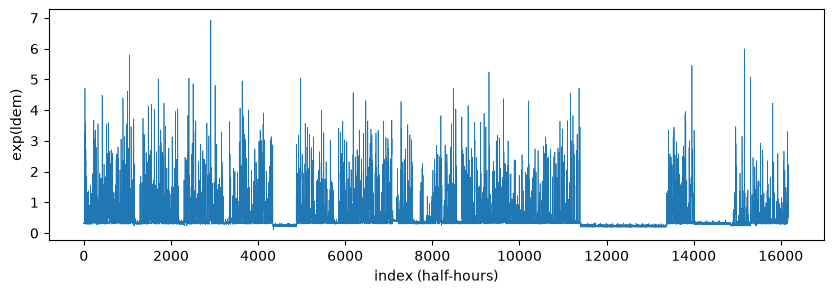

In [25]:
smart = r_data("smart_dat")

fig, ax = plt.subplots(figsize=(10, 3))
ax.plot(np.exp(smart["ldem"]), lw=0.5)
ax.set(xlabel="index (half-hours)", ylabel="exp(ldem)");

In [26]:
smart[["ldem", "doy", "tod", "mu_g", "mu_l", "lp_g", "lp_l", "mse_g_48", "mse_l_48",
       "test"]].head().round(2)

,ldem,doy,tod,mu_g,mu_l,lp_g,lp_l,mse_g_48,mse_l_48,test
0,-1.14,5.0,1,-0.89,-0.59,-0.47,-0.82,0.19,0.29,False
1,-1.19,5.0,2,-0.96,-0.59,-0.46,-0.93,0.19,0.29,False
2,-1.16,5.0,3,-1.03,-0.59,-0.41,-0.87,0.19,0.29,False
3,-1.13,5.0,4,-1.09,-0.59,-0.39,-0.80,0.19,0.29,False
4,-1.11,5.0,5,-1.14,-0.59,-0.38,-0.77,0.19,0.29,False


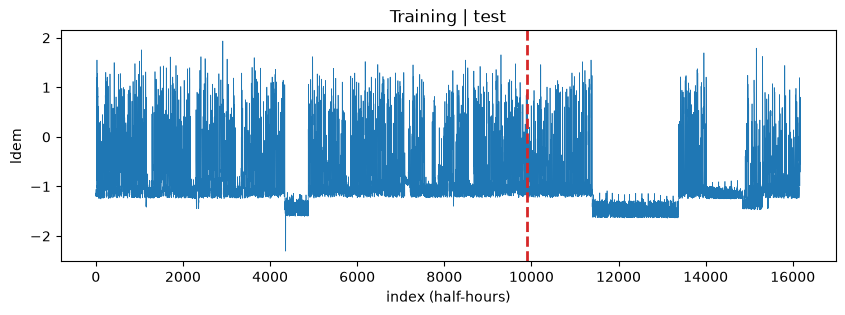

In [27]:
train = smart[~smart["test"]].reset_index(drop=True)
test = smart[smart["test"]].reset_index(drop=True)

fig, ax = plt.subplots(figsize=(10, 3))
ax.plot(smart["ldem"], lw=0.5)
ax.axvline(len(train), ls="--", color="C3", lw=2)
ax.set(xlabel="index (half-hours)", ylabel="ldem", title="Training | test");

Neither model is always better. In some periods the GAM is closer to the data, in
others the lagged Gaussian model is:

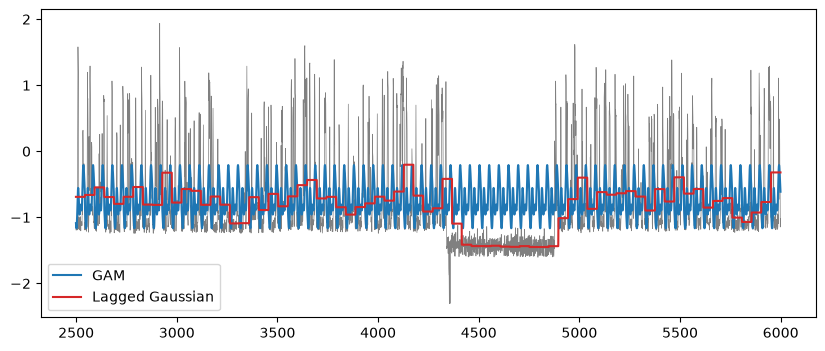

In [28]:
idx = slice(2499, 6000)  # R: 2500:6000 (R indexes from 1)
fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(train["ldem"].iloc[idx], color="grey", lw=0.5)
ax.plot(train["mu_g"].iloc[idx], color="C0", lw=1.5, label="GAM")
ax.plot(train["mu_l"].iloc[idx], color="C3", lw=1.5, label="Lagged Gaussian")
ax.legend(loc="lower left");

## The stacking model

**Stacking** combines the two forecasts into a mixture, with weights $w_g$ and
$w_l = 1 - w_g$:

$$
p(y) = w_g \, p_g(y) + w_l \, p_l(y).
$$

The weights are modelled with a GAM of each model's recent error (`mse_g_48`,
`mse_l_48`), so the stack can give more weight to whichever model has been doing better.
The `fam_stackProb` family from gamFactory takes the log densities `lp_g`, `lp_l` of the
two models and estimates the weights by maximising the likelihood of the mixture.

> ⚠️ **pymgcv limitation:** custom families like `fam_stackProb` from gamFactory are not
> available in pymgcv, so we fit this model with gamFactory through rpy2.

R:

```r
stack <- gam(list(ldem ~ s(mse_g_48, k = 5) + s(mse_l_48, k = 5)),
             family = fam_stackProb(cbind(train$lp_g, train$lp_l)), data = train)
```

In [29]:
ro.r("""
train <- smart_dat[smart_dat$test == FALSE, ]
test <- smart_dat[smart_dat$test == TRUE, ]
stack <- gam(list(ldem ~ s(mse_g_48, k = 5) + s(mse_l_48, k = 5)),
             family = fam_stackProb(cbind(train$lp_g, train$lp_l)),
             data = train)
stack_viz <- getViz(stack)
""")

weights_train = np.array(ro.r('predict(stack, type = "response")'))
pd.DataFrame(weights_train, columns=["w_gam", "w_lagged"]).head()

,w_gam,w_lagged
0,0.792635,0.207365
1,0.792635,0.207365
2,0.792635,0.207365
3,0.792635,0.207365
4,0.792635,0.207365


ALE plots show how each covariate changes the weight of the GAM forecast (`oind = 1`):
the weight of the GAM goes down when its recent error `mse_g_48` is high, and up when
the error of the other model, `mse_l_48`, is high.

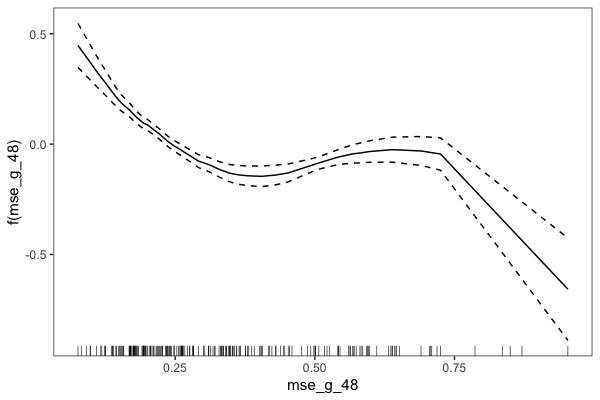

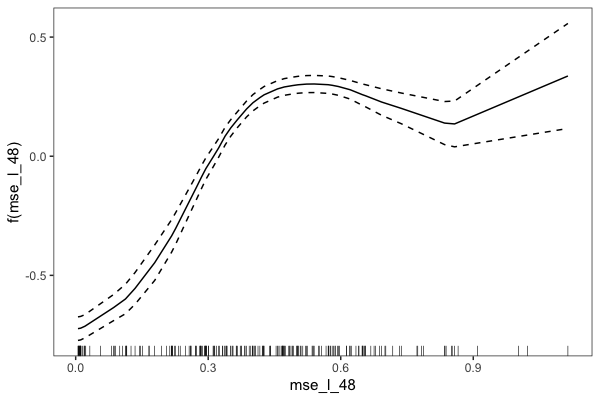

In [30]:
show_r_plot('print(plot(ALE(stack_viz, oind = 1, x = "mse_g_48", type = "response")))',
            width=6, height=4)
show_r_plot('print(plot(ALE(stack_viz, oind = 1, x = "mse_l_48", type = "response")))',
            width=6, height=4)

## Forecasting the test period

We predict the weights on the test set and combine the two forecasts:
$\mu_s = w_g \mu_g + w_l \mu_l$.

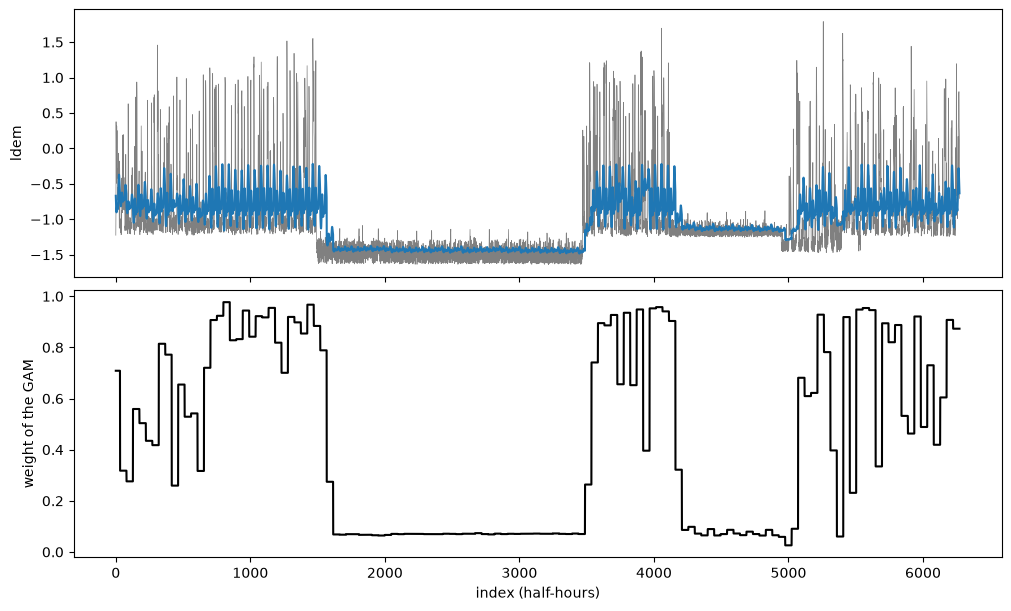

In [31]:
weights_test = np.array(ro.r('predict(stack, type = "response", newdata = test)'))
test["w_gam"] = weights_test[:, 0]
test["w_lagged"] = weights_test[:, 1]
test["mu_s"] = test["w_gam"] * test["mu_g"] + test["w_lagged"] * test["mu_l"]

fig, axes = plt.subplots(2, 1, figsize=(10, 6), sharex=True, layout="constrained")
axes[0].plot(test["ldem"], color="grey", lw=0.5)
axes[0].plot(test["mu_s"], color="C0", lw=1.5)
axes[0].set(ylabel="ldem")
axes[1].plot(test["w_gam"], color="black")
axes[1].set(ylabel="weight of the GAM", xlabel="index (half-hours)");

Finally, we compare the mean squared errors of the two models and of the stack on the test
set. As in R, the MSE of the stack is computed per day (`group_by(doy)` →
`groupby("doy")`) and then averaged. The stack has the lowest error.

In [32]:
daily_mse = (
    test.assign(se_s=(test["ldem"] - test["mu_s"]) ** 2)
    .groupby("doy", as_index=False)["se_s"].mean()
    .rename(columns={"se_s": "mse_s"})
)
test = test.merge(daily_mse, on="doy", how="left")

test[["mse_g", "mse_l", "mse_s"]].mean()

mse_g    0.416885
mse_l    0.228483
mse_s    0.200075
dtype: float64